# S&P 500 Stock Market Analysis
**Author:** Sharaf Zaman  
**Tools:** Python, Pandas, Matplotlib, NumPy, SciPy  

---

## Project Overview

This project analyzes historical S&P 500 index data to uncover long-term growth trends, measure market volatility, identify extreme market events, and explore the relationship between equity performance and interest rates.

### Key Questions
1. What does the long-term growth trajectory of the S&P 500 look like?
2. How volatile is the market on a daily and rolling basis?
3. When did the most extreme single-day gains and losses occur?
4. Is there a statistically significant relationship between the S&P 500 and long-term interest rates?
5. How do annual returns compare year over year?

---
## 1. Setup & Data Loading

We load the S&P 500 dataset directly from a public GitHub repository maintained by the `datasets` project. The dataset contains daily closing values of the S&P 500 index along with the long-term interest rate.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Plot styling
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['font.size'] = 11

# Load data
url = "https://raw.githubusercontent.com/datasets/s-and-p-500/master/data/data.csv"
df = pd.read_csv(url, parse_dates=['Date'])
df = df.sort_values('Date').reset_index(drop=True)

print(f"Dataset shape: {df.shape}")
print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"\nColumn names: {list(df.columns)}")
df.head()

Dataset shape: (1869, 10)
Date range: 1871-01-01 to 2026-09-01

Column names: ['Date', 'SP500', 'Dividend', 'Earnings', 'Consumer Price Index', 'Long Interest Rate', 'Real Price', 'Real Dividend', 'Real Earnings', 'PE10']


,Date,SP500,Dividend,Earnings,Consumer Price Index,Long Interest Rate,Real Price,Real Dividend,Real Earnings,PE10
0,1871-01-01,4.44,0.26,0.4,12.46,5.32,109.05,6.39,9.82,0.0
1,1871-02-01,4.50,0.26,0.4,12.84,5.32,107.25,6.20,9.53,0.0
2,1871-03-01,4.61,0.26,0.4,13.03,5.33,108.27,6.11,9.39,0.0
3,1871-04-01,4.74,0.26,0.4,12.56,5.33,115.54,6.34,9.75,0.0
4,1871-05-01,4.86,0.26,0.4,12.27,5.33,121.22,6.48,9.98,0.0


---
## 2. Data Cleaning & Preprocessing

Before any analysis, we check for missing values and engineer key features:
- **Monthly change**: raw point difference between consecutive months
- **Monthly return**: percentage change (used for volatility calculations)
- **Year / Month**: for time-based aggregation

In [10]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())

# Remove rows where the S&P 500 value is missing
df = df.dropna(subset=['SP500']).copy()

# Feature engineering
df['monthly_change'] = df['SP500'].diff()
df['monthly_return'] = df['SP500'].pct_change() * 100

# Time-based features
df['year'] = df['Date'].dt.year
df['month'] = df['Date'].dt.month

# Rolling volatility using a 12-month window
df['rolling_vol_12'] = (df['monthly_return'].rolling(window=12).std())

# Annualized volatility
df['annualized_vol_12'] = df['rolling_vol_12'] * np.sqrt(12)

# 50-month and 200-month moving averages
df['SMA_50'] = df['SP500'].rolling(window=50).mean()
df['SMA_200'] = df['SP500'].rolling(window=200).mean()

print(f"\nRows after cleaning: {len(df)}")

print("\nDate range:")
print(f"{df['Date'].min().date()} to {df['Date'].max().date()}")

print("\nBasic statistics for S&P 500:")
print(df['SP500'].describe().round(2))

Missing values per column:
Date                    0
SP500                   0
Dividend                0
Earnings                0
Consumer Price Index    0
Long Interest Rate      0
Real Price              0
Real Dividend           0
Real Earnings           0
PE10                    0
dtype: int64

Rows after cleaning: 1869

Date range:
1871-01-01 to 2026-09-01

Basic statistics for S&P 500:
count    1869.00
mean      486.48
std      1126.06
min         2.73
25%         8.05
50%        20.00
75%       268.00
max      7711.32
Name: SP500, dtype: float64


---
## 3. Long-Term Growth Trend with Moving Averages

The chart below shows the historical S&P 500 index value alongside its **50-month** and **200-month simple moving averages (SMA)**.

- The **50-month SMA** captures the medium-term trend.
- The **200-month SMA** captures the long-term trend.
- When the index is above its 200-month SMA, it generally indicates stronger long-term upward momentum.

A **golden cross** occurs when the 50-month SMA crosses above the 200-month SMA. A **death cross** occurs when the 50-month SMA crosses below the 200-month SMA.

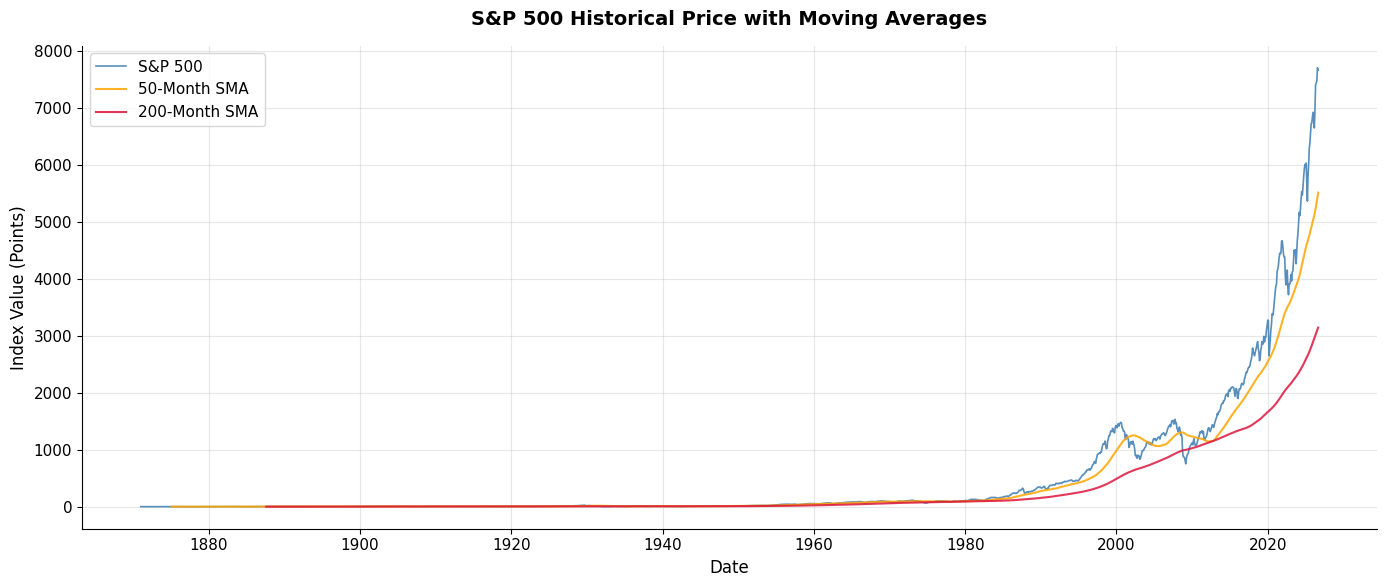

Starting value           : 4.44
Ending value             : 7,669.41
Cumulative price return : 172,634.5%


In [11]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    df['Date'],
    df['SP500'],
    color='steelblue',
    linewidth=1.2,
    label='S&P 500',
    alpha=0.9
)

ax.plot(
    df['Date'],
    df['SMA_50'],
    color='orange',
    linewidth=1.5,
    label='50-Month SMA',
    alpha=0.85
)

ax.plot(
    df['Date'],
    df['SMA_200'],
    color='crimson',
    linewidth=1.5,
    label='200-Month SMA',
    alpha=0.85
)

ax.set_title(
    'S&P 500 Historical Price with Moving Averages',
    fontsize=14,
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Index Value (Points)', fontsize=12)
ax.legend(fontsize=11)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.savefig('sp500_trend.png', dpi=150, bbox_inches='tight')
plt.show()

# Growth summary
first_val = df['SP500'].iloc[0]
last_val = df['SP500'].iloc[-1]

cumulative_price_return = (
    (last_val - first_val) / first_val
) * 100

print(f"Starting value           : {first_val:,.2f}")
print(f"Ending value             : {last_val:,.2f}")
print(f"Cumulative price return : {cumulative_price_return:,.1f}%")

---
## 4. Daily Returns & Extreme Market Events

Daily percentage returns reveal the day-to-day volatility of the market. We identify the **top 5 single-day gains and losses**, which often correspond to major economic events (crashes, crises, recovery rallies).

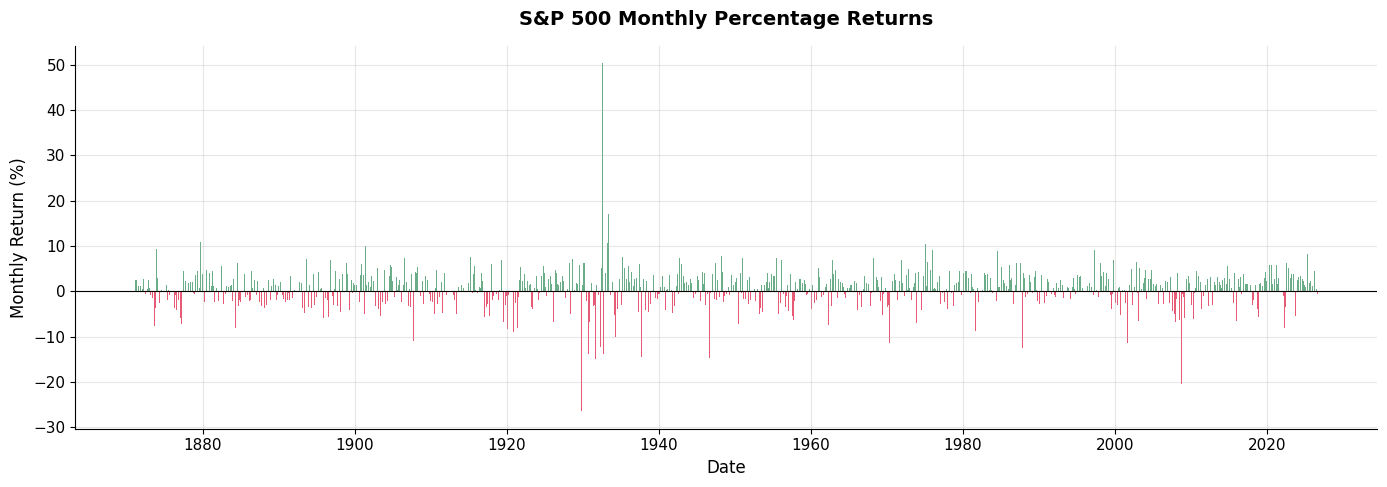

TOP 5 MONTHLY GAINS
      Date  SP500  monthly_change  monthly_return
1932-08-01   7.53            2.52       50.299401
1933-05-01   8.87            1.98       28.737300
1938-07-01  12.24            2.03       19.882468
1933-06-01  10.39            1.52       17.136415
2009-04-01 848.15           91.02       12.021714

TOP 5 MONTHLY LOSSES
      Date       SP500  monthly_change  monthly_return
1929-11-01   20.580000       -7.410000      -26.473741
1932-04-01    6.280000       -1.980000      -23.970944
2008-10-01  968.800000     -248.150000      -20.391142
2020-03-01 2652.393636     -624.920574      -19.068070
1931-12-01    8.440000       -1.950000      -18.768046


In [12]:
fig, ax = plt.subplots(figsize=(14, 5))

# Color positive monthly returns green and negative monthly returns red
colors = [
    'crimson' if x < 0 else 'seagreen'
    for x in df['monthly_return'].fillna(0)
]

ax.bar(
    df['Date'],
    df['monthly_return'],
    color=colors,
    width=20,
    alpha=0.7
)

ax.axhline(0, color='black', linewidth=0.8)

ax.set_title(
    'S&P 500 Monthly Percentage Returns',
    fontsize=14,
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Monthly Return (%)', fontsize=12)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.savefig('sp500_monthly_returns.png', dpi=150, bbox_inches='tight')
plt.show()

# Top 5 monthly gains and losses
cols = ['Date', 'SP500', 'monthly_change', 'monthly_return']

print("=" * 60)
print("TOP 5 MONTHLY GAINS")
print("=" * 60)
print(
    df.nlargest(5, 'monthly_return')[cols]
    .to_string(index=False)
)

print("\n" + "=" * 60)
print("TOP 5 MONTHLY LOSSES")
print("=" * 60)
print(
    df.nsmallest(5, 'monthly_return')[cols]
    .to_string(index=False)
)

---
## 5. Monthly Return Distribution and Normality Test

This section examines how the S&P 500's monthly returns are distributed.

The histogram shows how often different monthly returns occurred. The red curve represents what the returns would look like if they followed a normal distribution.

The Q-Q plot and Shapiro-Wilk test help us determine whether the monthly returns are normally distributed.

- **H₀:** Monthly returns are normally distributed
- **H₁:** Monthly returns are not normally distributed

Financial returns often have **fat tails**, meaning unusually large gains and losses happen more often than a normal distribution would predict.

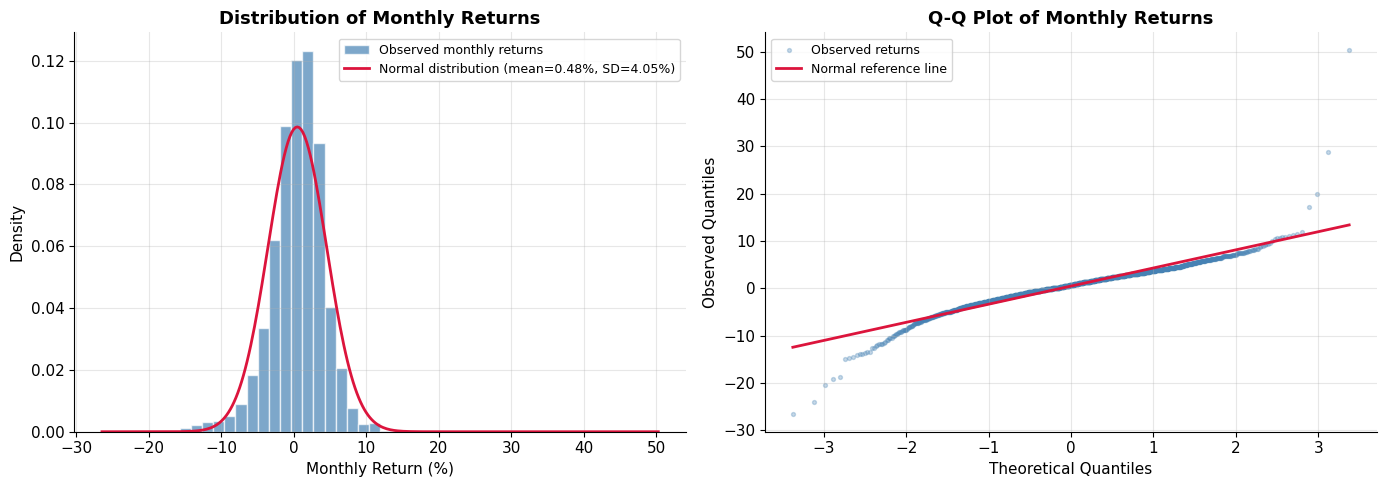

Shapiro-Wilk Test on Monthly Returns (n=1868)
Test statistic: 0.8993
p-value: 0.000000
Conclusion: Reject H₀ — monthly returns are not normally distributed.

Descriptive statistics:
Mean: 0.4815%
Standard deviation: 4.0451%
Skewness: 0.3723
Excess kurtosis: 16.7496


In [13]:
# Remove the missing first monthly return
returns_clean = df['monthly_return'].dropna()

# Create two graphs
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of monthly returns
ax1 = axes[0]

ax1.hist(
    returns_clean,
    bins=50,
    color='steelblue',
    edgecolor='white',
    alpha=0.7,
    density=True,
    label='Observed monthly returns'
)

# Calculate the mean and standard deviation
mu = returns_clean.mean()
sigma = returns_clean.std()

# Create a normal distribution curve using the same mean and standard deviation
x = np.linspace(
    returns_clean.min(),
    returns_clean.max(),
    300
)

ax1.plot(
    x,
    stats.norm.pdf(x, mu, sigma),
    color='crimson',
    linewidth=2,
    label=f'Normal distribution (mean={mu:.2f}%, SD={sigma:.2f}%)'
)

ax1.set_title('Distribution of Monthly Returns', fontsize=13, fontweight='bold')
ax1.set_xlabel('Monthly Return (%)', fontsize=11)
ax1.set_ylabel('Density', fontsize=11)
ax1.legend(fontsize=9)

# Q-Q plot
ax2 = axes[1]

(osm, osr), (slope, intercept, r) = stats.probplot(
    returns_clean,
    dist='norm'
)

ax2.scatter(
    osm,
    osr,
    alpha=0.3,
    s=8,
    color='steelblue',
    label='Observed returns'
)

ax2.plot(
    osm,
    slope * np.array(osm) + intercept,
    color='crimson',
    linewidth=2,
    label='Normal reference line'
)

ax2.set_title('Q-Q Plot of Monthly Returns', fontsize=13, fontweight='bold')
ax2.set_xlabel('Theoretical Quantiles', fontsize=11)
ax2.set_ylabel('Observed Quantiles', fontsize=11)
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig('monthly_return_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# Shapiro-Wilk normality test
stat, p_value = stats.shapiro(returns_clean)

print(f"Shapiro-Wilk Test on Monthly Returns (n={len(returns_clean)})")
print(f"Test statistic: {stat:.4f}")
print(f"p-value: {p_value:.6f}")

if p_value < 0.05:
    print("Conclusion: Reject H₀ — monthly returns are not normally distributed.")
else:
    print("Conclusion: Fail to reject H₀ — there is not enough evidence to say returns are not normally distributed.")

print("\nDescriptive statistics:")
print(f"Mean: {mu:.4f}%")
print(f"Standard deviation: {sigma:.4f}%")
print(f"Skewness: {returns_clean.skew():.4f}")
print(f"Excess kurtosis: {returns_clean.kurtosis():.4f}")

---
## 6. Rolling Volatility (12-Month Window)

Rolling volatility measures how much the S&P 500's monthly returns vary over time.

For each month, we calculate the standard deviation of the previous 12 monthly returns. Higher volatility means the market's returns were changing more dramatically, while lower volatility means the returns were more stable.

The volatility is annualized so it can be interpreted on a yearly scale. Volatility spikes often occur during periods of major market stress.

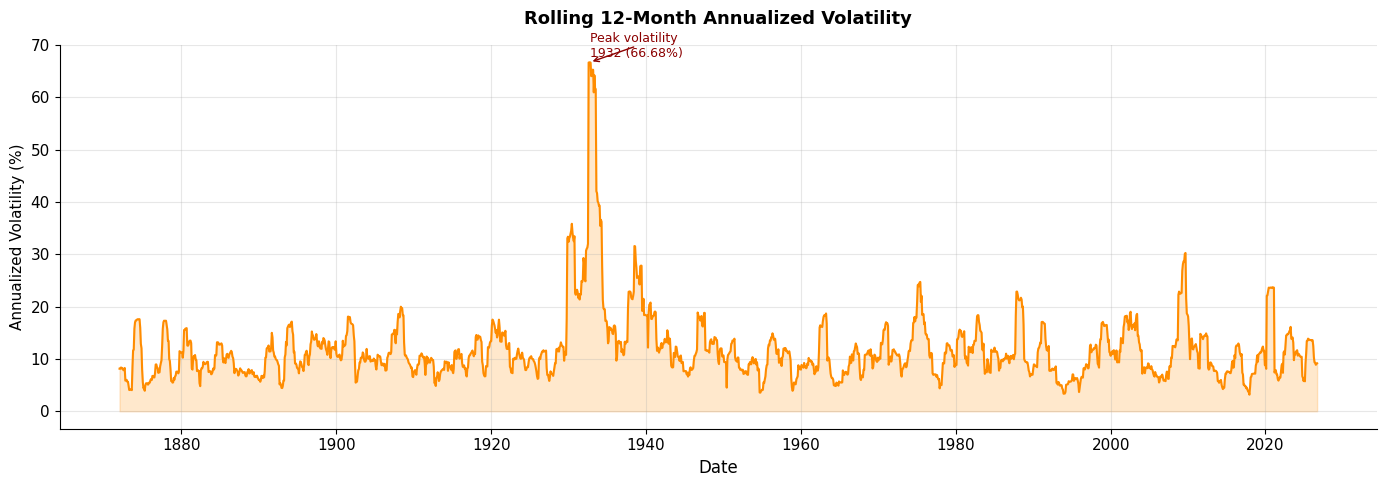

Average annualized volatility: 11.84%
Peak annualized volatility: 66.68% around 1932-10-01


In [14]:
# Find the date with the highest annualized volatility
peak_idx = df['annualized_vol_12'].idxmax()
peak_date = df.loc[peak_idx, 'Date']
peak_vol = df.loc[peak_idx, 'annualized_vol_12']

# Create the chart
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    df['Date'],
    df['annualized_vol_12'],
    color='darkorange',
    linewidth=1.5
)

ax.fill_between(
    df['Date'],
    df['annualized_vol_12'],
    alpha=0.2,
    color='darkorange'
)

# Mark the highest-volatility period
ax.annotate(
    f'Peak volatility\n{peak_date.year} ({peak_vol:.2f}%)',
    xy=(peak_date, peak_vol),
    xytext=(peak_date, peak_vol + 1),
    fontsize=9,
    color='darkred',
    arrowprops=dict(
        arrowstyle='->',
        color='darkred'
    )
)

ax.set_title(
    'Rolling 12-Month Annualized Volatility',
    fontsize=13,
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Annualized Volatility (%)', fontsize=11)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.savefig(
    'rolling_annualized_volatility.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

print(
    f"Average annualized volatility: "
    f"{df['annualized_vol_12'].mean():.2f}%"
)

print(
    f"Peak annualized volatility: "
    f"{peak_vol:.2f}% around {peak_date.date()}"
)

---
## 7. Year-over-Year Annual Returns

We compare the S&P 500's final value from each complete year with the final value from the previous year.

This shows whether the index increased or decreased during each year and helps us identify the strongest and weakest annual performances.

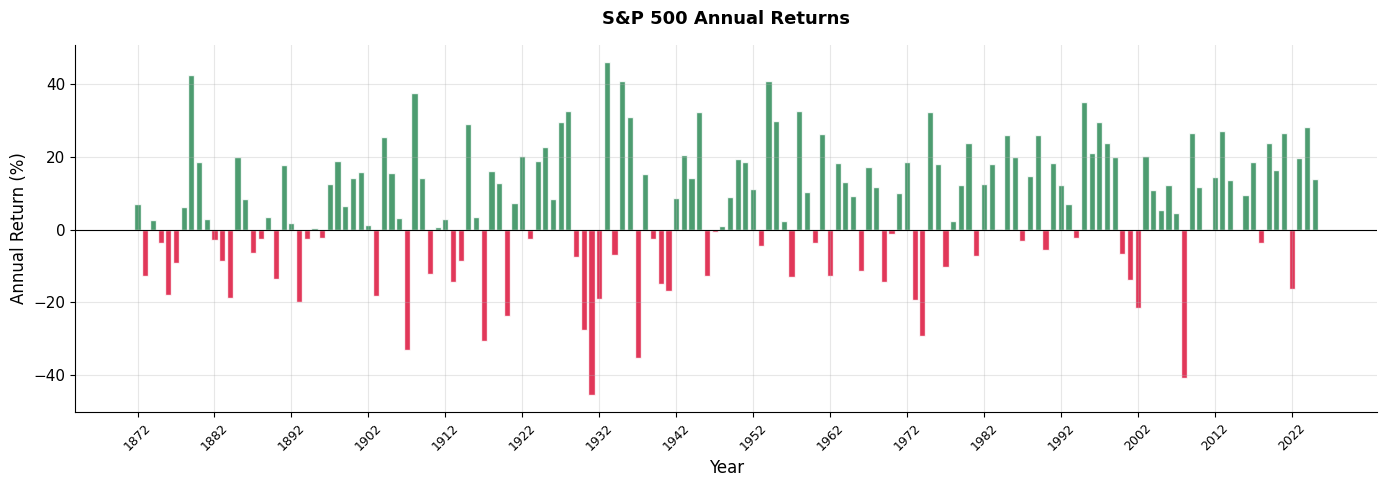

Best year: 1933 (46.2%)
Worst year: 1931 (-45.6%)
Average annual return: 6.42%
Positive years: 101 / 154


In [15]:
# Use the final monthly value from each complete year
complete_years = (
    df.groupby('year')['month']
    .max()
)

complete_years = complete_years[
    complete_years == 12
].index

year_end_values = (
    df[df['year'].isin(complete_years)]
    .groupby('year')['SP500']
    .last()
)

# Calculate each year's return compared with the previous year
annual = year_end_values.pct_change() * 100
annual = annual.dropna().reset_index(name='annual_return')

# Color positive years green and negative years red
bar_colors = [
    'seagreen' if value >= 0 else 'crimson'
    for value in annual['annual_return']
]

# Create the chart
fig, ax = plt.subplots(figsize=(14, 5))

ax.bar(
    annual['year'],
    annual['annual_return'],
    color=bar_colors,
    edgecolor='white',
    alpha=0.85
)

ax.axhline(0, color='black', linewidth=0.8)

ax.set_title(
    'S&P 500 Annual Returns',
    fontsize=13,
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Annual Return (%)', fontsize=12)

# Show every tenth year to keep the x-axis readable
ax.set_xticks(annual['year'][::10])
ax.set_xticklabels(
    annual['year'][::10],
    rotation=45,
    fontsize=9
)

plt.tight_layout()
plt.savefig(
    'annual_returns.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

# Summary statistics
best_year = annual.loc[
    annual['annual_return'].idxmax()
]

worst_year = annual.loc[
    annual['annual_return'].idxmin()
]

print(
    f"Best year: {int(best_year['year'])} "
    f"({best_year['annual_return']:.1f}%)"
)

print(
    f"Worst year: {int(worst_year['year'])} "
    f"({worst_year['annual_return']:.1f}%)"
)

print(
    f"Average annual return: "
    f"{annual['annual_return'].mean():.2f}%"
)

print(
    f"Positive years: "
    f"{(annual['annual_return'] > 0).sum()} / {len(annual)}"
)

---
## 8. Relationship Between Monthly Returns and Interest-Rate Changes

This section examines whether changes in long-term interest rates are associated with monthly S&P 500 returns.

We use Pearson correlation, Spearman correlation, and a simple linear regression to measure the relationship.

This analysis measures association, not causation. A relationship between interest-rate changes and market returns does not prove that one directly causes the other.

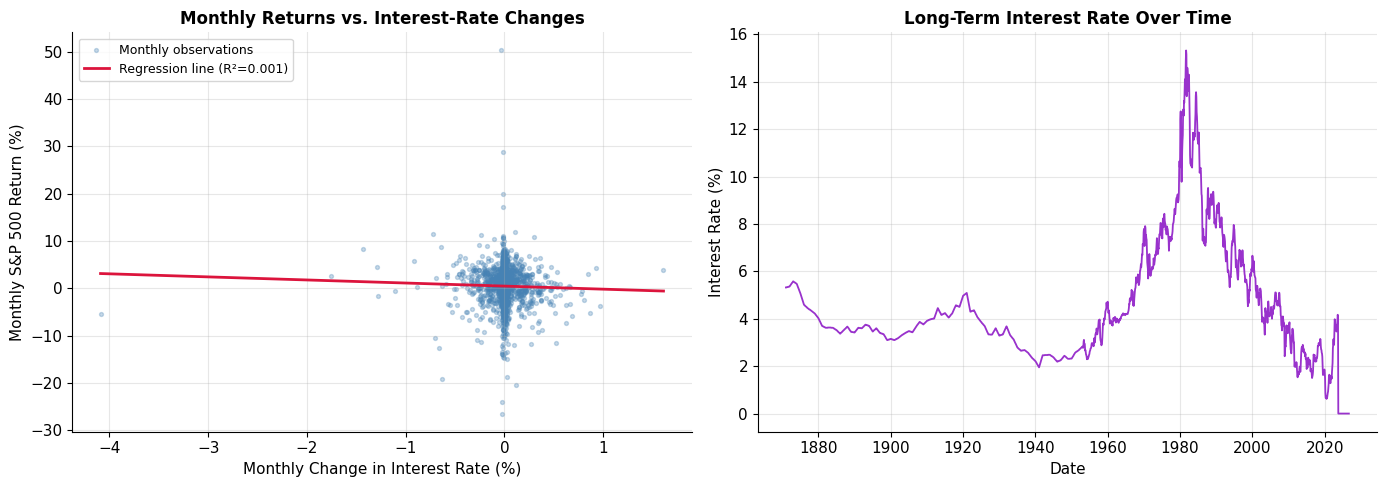

Pearson correlation: r = -0.0323 (p = 0.1624)
Spearman correlation: r = -0.0452 (p = 0.0509)
Regression R²: 0.0010
Conclusion: There is not enough evidence of a statistically significant association.


In [16]:
# Select the interest-rate column
rate_col = 'Long Interest Rate'

# Create a dataset with monthly returns and interest-rate changes
corr_df = df[['Date', 'monthly_return', rate_col]].copy()

corr_df['rate_change'] = corr_df[rate_col].diff()

# Remove missing values
corr_df = corr_df.dropna(
    subset=['monthly_return', 'rate_change']
)

# Calculate correlations
pearson_r, p_pearson = stats.pearsonr(
    corr_df['monthly_return'],
    corr_df['rate_change']
)

spearman_r, p_spearman = stats.spearmanr(
    corr_df['monthly_return'],
    corr_df['rate_change']
)

# Run a simple linear regression
slope, intercept, r_value, p_value, std_err = stats.linregress(
    corr_df['rate_change'],
    corr_df['monthly_return']
)

# Create regression line
x_line = np.linspace(
    corr_df['rate_change'].min(),
    corr_df['rate_change'].max(),
    200
)

y_line = slope * x_line + intercept

# Create two charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatterplot with regression line
ax1 = axes[0]

ax1.scatter(
    corr_df['rate_change'],
    corr_df['monthly_return'],
    alpha=0.3,
    s=8,
    color='steelblue',
    label='Monthly observations'
)

ax1.plot(
    x_line,
    y_line,
    color='crimson',
    linewidth=2,
    label=f'Regression line (R²={r_value**2:.3f})'
)

ax1.set_title(
    'Monthly Returns vs. Interest-Rate Changes',
    fontsize=12,
    fontweight='bold'
)

ax1.set_xlabel('Monthly Change in Interest Rate (%)', fontsize=11)
ax1.set_ylabel('Monthly S&P 500 Return (%)', fontsize=11)
ax1.legend(fontsize=9)

# Interest rate over time
ax2 = axes[1]

ax2.plot(
    df['Date'],
    df[rate_col],
    color='darkorchid',
    linewidth=1.3
)

ax2.set_title(
    'Long-Term Interest Rate Over Time',
    fontsize=12,
    fontweight='bold'
)

ax2.set_xlabel('Date', fontsize=11)
ax2.set_ylabel('Interest Rate (%)', fontsize=11)
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.savefig(
    'correlation_analysis.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

# Print results
print(
    f"Pearson correlation: r = {pearson_r:.4f} "
    f"(p = {p_pearson:.4f})"
)

print(
    f"Spearman correlation: r = {spearman_r:.4f} "
    f"(p = {p_spearman:.4f})"
)

print(
    f"Regression R²: {r_value**2:.4f}"
)

if p_pearson < 0.05:
    print(
        "Conclusion: There is a statistically significant association "
        "between monthly S&P 500 returns and interest-rate changes."
    )
else:
    print(
        "Conclusion: There is not enough evidence of a statistically "
        "significant association."
    )

---
## 9. Crash Month Analysis

We define a crash month as a month when the S&P 500 falls by at least 10%.

This section identifies the years with the most crash months and examines the distribution of the largest monthly declines.

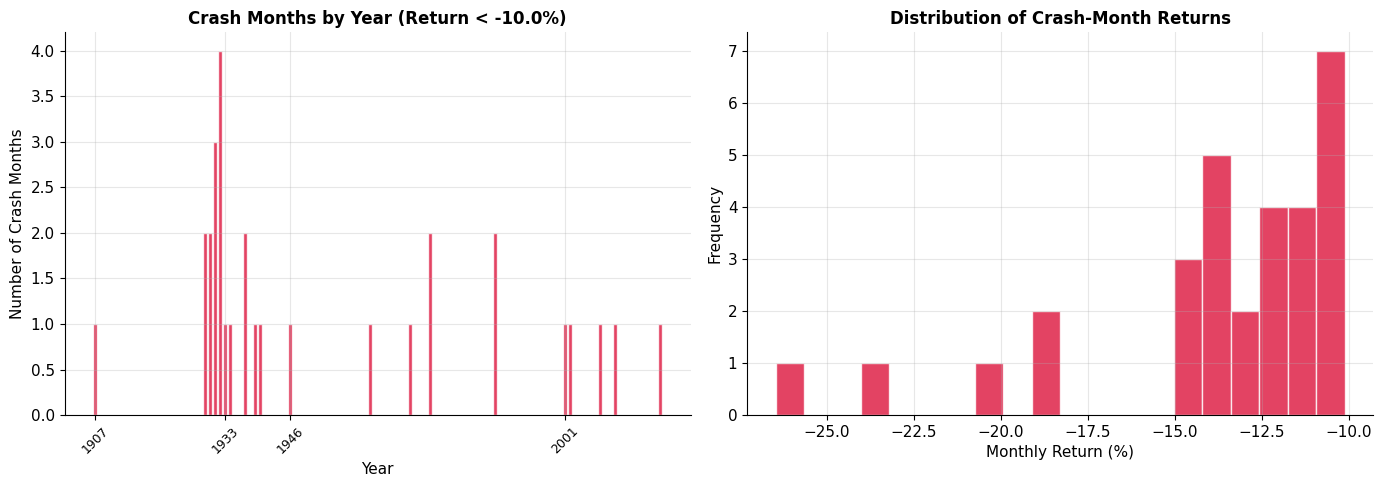

Total crash months (< -10.0%): 30

Worst 10 crash months:
      Date       SP500  monthly_return
1929-11-01   20.580000      -26.473741
1932-04-01    6.280000      -23.970944
2008-10-01  968.800000      -20.391142
2020-03-01 2652.393636      -19.068070
1931-12-01    8.440000      -18.768046
1931-09-01   11.830000      -14.892086
1946-09-01   15.090000      -14.745763
1937-10-01   12.280000      -14.544189
1937-09-01   14.370000      -14.157706
1932-10-01    7.120000      -13.801453


In [18]:
# Define a crash month as a monthly return below -10%
threshold = -10.0

crash_months = df[
    df['monthly_return'] < threshold
].copy()

# Count crash months by year
crash_by_year = (
    crash_months
    .groupby('year')
    .size()
    .reset_index(name='crash_count')
)

# Create two charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Number of crash months by year
axes[0].bar(
    crash_by_year['year'],
    crash_by_year['crash_count'],
    color='crimson',
    alpha=0.8,
    edgecolor='white'
)

axes[0].set_title(
    f'Crash Months by Year (Return < {threshold}%)',
    fontsize=12,
    fontweight='bold'
)

axes[0].set_xlabel('Year', fontsize=11)
axes[0].set_ylabel('Number of Crash Months', fontsize=11)

# Show every fifth year to keep the axis readable
axes[0].set_xticks(crash_by_year['year'][::5])
axes[0].set_xticklabels(
    crash_by_year['year'][::5],
    rotation=45,
    fontsize=9
)

# Distribution of crash-month returns
axes[1].hist(
    crash_months['monthly_return'],
    bins=20,
    color='crimson',
    edgecolor='white',
    alpha=0.8
)

axes[1].set_title(
    'Distribution of Crash-Month Returns',
    fontsize=12,
    fontweight='bold'
)

axes[1].set_xlabel('Monthly Return (%)', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)

plt.tight_layout()
plt.savefig(
    'crash_month_analysis.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

# Print summary results
print(
    f"Total crash months "
    f"(< {threshold}%): {len(crash_months)}"
)

print("\nWorst 10 crash months:")

print(
    crash_months
    .nsmallest(10, 'monthly_return')
    [['Date', 'SP500', 'monthly_return']]
    .to_string(index=False)
)

---
## 10. Summary & Key Findings

This analysis examined historical monthly S&P 500 data to study long-term growth, returns, volatility, normality, interest-rate changes, and large market declines.

### Key Findings

| Finding | Result |
|---|---|
| **Long-term growth** | The S&P 500 showed substantial cumulative nominal price growth over the period analyzed. This is a price return and does not include dividends. |
| **Monthly returns** | Monthly returns were not normally distributed. The Shapiro-Wilk test rejected the assumption of normality. |
| **Fat tails** | Excess kurtosis was greater than zero, showing that unusually large monthly gains and losses occurred more often than a normal distribution would predict. |
| **Volatility** | Average annualized volatility was approximately 11.84%. The highest volatility occurred around October 1932 at approximately 66.68%. |
| **Annual returns** | The S&P 500 had positive returns in 101 of 154 complete years analyzed. The best year was 1933 with a 46.2% return, while the worst year was 1931 with a −45.6% return. |
| **Interest-rate changes** | The analysis found no statistically significant association between monthly S&P 500 returns and monthly changes in long-term interest rates. |
| **Crash months** | There were 30 months with returns below −10%. These large declines were concentrated in several major periods of market stress. |

### Limitations

- The dataset contains monthly index-level data, so daily and intraday market movements are not analyzed.
- The S&P 500 values represent price changes and do not include reinvested dividends.
- The historical dataset may include reconstructed index values from periods before the modern S&P 500 existed.
- Correlation does not prove causation. Other economic factors may influence both interest rates and market returns.
- A crash month was defined as a monthly return below −10%. Different thresholds could produce different results.

### Potential Extensions

- Include dividend data to calculate total investment returns.
- Compare market performance across different interest-rate environments.
- Add inflation data to calculate real, inflation-adjusted returns.
- Analyze sector-level data to determine which industries contribute most to market volatility.